# TSP restringido — QUBO + QAOA (Qiskit)

Mismo QUBO reducido que Simulated Annealing (una variable binaria por ruta candidata,
seleccionar exactamente una). Se resuelve con **QAOA** (`p=3`) en Aer.


In [1]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit_aer.primitives import EstimatorV2 as AerEstimator, SamplerV2 as AerSampler
from scipy.optimize import minimize


In [2]:
nodes = [0, 1, 2, 3, 4]
origin = 0
d02 = 4
dist = {
    (0, 1): 3, (0, 2): d02, (0, 3): 4, (0, 4): 2,
    (1, 2): 3, (1, 3): 4, (2, 3): 1, (2, 4): 6,
}
for (i, j), value in list(dist.items()):
    dist[(j, i)] = value
BIG_M = 100

def edge_exists(i, j):
    return (i, j) in dist

def cost(i, j):
    if i == j:
        return BIG_M
    return dist.get((i, j), BIG_M)

def route_cost(route):
    return sum(cost(route[i], route[i + 1]) for i in range(len(route) - 1))

def is_valid_route(route):
    if route[0] != origin or route[-1] != origin:
        return False
    if sorted(route[1:-1]) != [1, 2, 3, 4]:
        return False
    return route[2] == 2

def generate_candidate_routes():
    candidates = []
    for perm in itertools.permutations([1, 2, 3, 4]):
        route = [origin] + list(perm) + [origin]
        if is_valid_route(route):
            candidates.append({
                "route": route,
                "cost": route_cost(route),
                "uses_invalid_edges": any(not edge_exists(route[i], route[i + 1]) for i in range(len(route) - 1)),
            })
    return candidates

candidates = generate_candidate_routes()
OPTIMAL = min((c for c in candidates if not c["uses_invalid_edges"]), key=lambda c: c["cost"])
OPTIMAL_COST = float(OPTIMAL["cost"])
print("Candidatas:", len(candidates), "| óptimo estricto:", OPTIMAL)

def resolve_metrics_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization" / "TSPOptimization"
        if root.is_dir():
            d = root / "metrics"
            d.mkdir(parents=True, exist_ok=True)
            return d
    d = Path.cwd().resolve() / "Notebooks" / "Optimization" / "TSPOptimization" / "metrics"
    d.mkdir(parents=True, exist_ok=True)
    return d

def save_tsp_metrics(payload: dict, filename: str):
    path = resolve_metrics_dir() / filename
    path.write_text(json.dumps(payload, indent=2))
    print("Saved:", path)
    return path


Candidatas: 6 | óptimo estricto: {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}


## QUBO → Ising y QAOA


In [3]:
# QUBO: E(y)= sum c_k y_k + P (1 - sum y_k)^2
PENALTY = 100.0
m = len(candidates)
costs = np.array([c["cost"] for c in candidates], dtype=float)

# Expand to quadratic form: const + lin·y + y^T Q y
# (1-sum y)^2 = 1 - 2 sum y + sum_i y_i^2 + 2 sum_{i<j} y_i y_j
# with y_i^2=y_i => lin_i += P, quad_ij += 2P, const += P; plus costs on lin
const = PENALTY
lin = costs - 2 * PENALTY + PENALTY  # costs - 2P + P (from y^2) = costs - P
# Wait: (1 - S)^2 = 1 - 2S + S^2, S^2 = sum y_i + 2 sum i<j y_i y_j
# => const=P, lin_i = c_i - 2P + P = c_i - P, quad_ij = 2P
lin = costs - PENALTY
quad = {(i, j): 2 * PENALTY for i in range(m) for j in range(i + 1, m)}

def qubo_energy(bits):
    val = const + float(np.dot(lin, bits))
    for (i, j), q in quad.items():
        val += q * bits[i] * bits[j]
    return val

# Ising via x=(1-Z)/2
sparse = []
for i in range(m):
    sparse.append(("Z", [i], -lin[i] / 2))
for (i, j), qv in quad.items():
    sparse += [("Z", [i], -qv / 4), ("Z", [j], -qv / 4), ("ZZ", [i, j], qv / 4)]
H_cost = SparsePauliOp.from_sparse_list(sparse, num_qubits=m).simplify()
print("Términos Pauli:", len(H_cost))


Términos Pauli: 21


In [4]:
P_LAYERS = 2
N_RUNS = 5
RESTARTS = 8
SHOTS = 3000
COBYLA_MAXITER = 80

def run_qaoa(seed: int):
    t0 = time.perf_counter()
    ansatz = QAOAAnsatz(cost_operator=H_cost, reps=P_LAYERS)
    qaoa = transpile(ansatz, basis_gates=["h", "rx", "rz", "rzz", "cx"], optimization_level=1)
    est = AerEstimator(options={"backend_options": {"method": "statevector"}})
    n_evals = [0]
    def energy(theta):
        n_evals[0] += 1
        return float(est.run([(qaoa, H_cost, theta)]).result()[0].data.evs)
    rng = np.random.default_rng(seed)
    best_theta, best_e = None, np.inf
    for _ in range(RESTARTS):
        res = minimize(energy, rng.uniform(0, np.pi, qaoa.num_parameters), method="COBYLA",
                       options={"maxiter": COBYLA_MAXITER, "rhobeg": 0.5})
        if res.fun < best_e:
            best_e, best_theta = res.fun, res.x
    circ = qaoa.copy(); circ.measure_all()
    counts = AerSampler(options={"backend_options": {"method": "statevector"}}).run(
        [(circ, best_theta)], shots=SHOTS
    ).result()[0].data.meas.get_counts()
    # little-endian decode
    def bits_of(s):
        return [int(s[m - 1 - i]) for i in range(m)]
    best_s = min(counts, key=lambda s: qubo_energy(bits_of(s)))
    bits = bits_of(best_s)
    elapsed = time.perf_counter() - t0
    selected = None
    if sum(bits) == 1:
        selected = candidates[int(np.argmax(bits))]
    feasible = selected is not None and (not selected["uses_invalid_edges"])
    cost = float(selected["cost"]) if selected else float("nan")
    success = bool(feasible and abs(cost - OPTIMAL_COST) < 1e-9)
    return {
        "seed": seed,
        "bits": bits,
        "route": None if selected is None else selected["route"],
        "cost": None if selected is None else cost,
        "feasible": feasible,
        "success": success,
        "gap": None if selected is None else cost - OPTIMAL_COST,
        "time_s": float(elapsed),
        "energy_evals": n_evals[0],
        "expected_energy": float(best_e),
        "circuit_depth": int(qaoa.depth()),
    }

rows = [run_qaoa(seed) for seed in range(N_RUNS)]
for r in rows:
    print(f"seed={r['seed']} success={r['success']} cost={r['cost']} time={r['time_s']:.2f}s")

costs = np.array([r["cost"] for r in rows if r["cost"] is not None], dtype=float)
times = np.array([r["time_s"] for r in rows], dtype=float)
payload = {
    "problem": "tsp",
    "solver": "qaoa",
    "family": "quantum_inspired",
    "protocol": {"n_runs": N_RUNS, "p": P_LAYERS, "restarts": RESTARTS, "shots": SHOTS,
                 "cobyla_maxiter": COBYLA_MAXITER, "n_qubits": m, "backend": "aer_statevector"},
    "instance": {"nodes": nodes, "origin": origin, "d02": d02},
    "quality": {
        "optimal_cost": OPTIMAL_COST,
        "optimal_route": OPTIMAL["route"],
        "cost_mean": float(np.nanmean(costs)) if len(costs) else None,
        "cost_best": float(np.nanmin(costs)) if len(costs) else None,
        "gap_mean": None if not len(costs) else float(np.nanmean(costs - OPTIMAL_COST)),
    },
    "success_rate": float(np.mean([r["success"] for r in rows])),
    "time_s": {"mean": float(np.mean(times)), "std": float(np.std(times)), "total": float(np.sum(times))},
    "effort": {"energy_evals_mean": float(np.mean([r["energy_evals"] for r in rows])),
               "p": P_LAYERS, "shots": SHOTS, "circuit_depth": rows[0]["circuit_depth"]},
    "runs": rows,
}
save_tsp_metrics(payload, "qaoa_tsp.json")


seed=0 success=True cost=16.0 time=1.20s
seed=1 success=True cost=16.0 time=1.15s
seed=2 success=True cost=16.0 time=1.09s
seed=3 success=True cost=16.0 time=1.09s
seed=4 success=True cost=16.0 time=1.08s
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/metrics/qaoa_tsp.json


PosixPath('/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/metrics/qaoa_tsp.json')

## Storytelling plots

Figuras para documento/slides → `figures/`.


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/figures/instance_tsp_graph.png


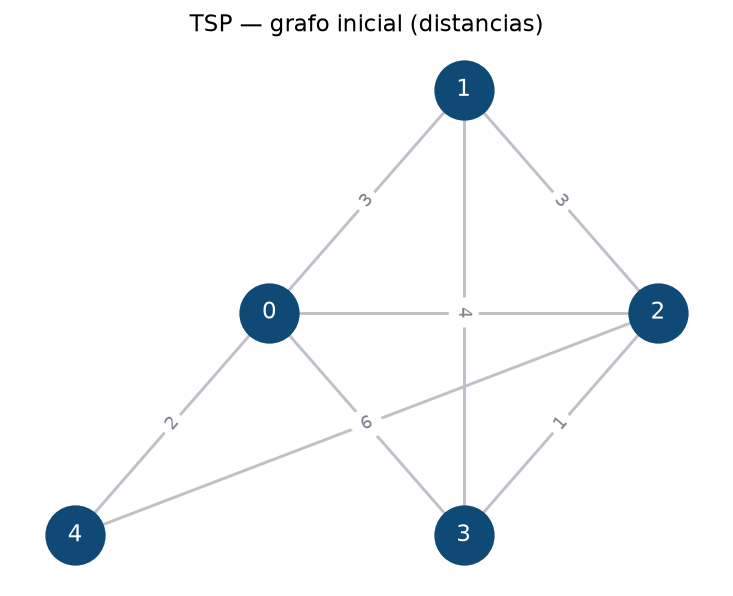

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/figures/qaoa_tsp_route.png


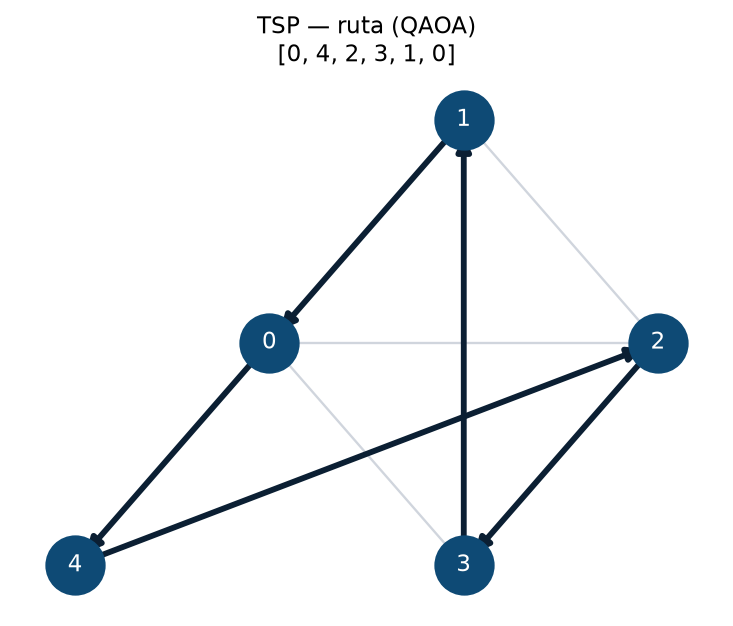

In [5]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import (
    resolve_figures_dir,
    plot_tsp_instance, plot_tsp_route,
)

figures_dir = resolve_figures_dir("Optimization", "TSPOptimization")
plot_tsp_instance(nodes, dist, figures_dir, stem="instance")
# ruta del solver: payload runs o sol
_route = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("route") is not None]
    if _runs:
        _route = min(_runs, key=lambda r: float(r.get("cost", 1e18))).get("route")
if _route is None and "sol" in globals():
    _route = sol["route"] if isinstance(sol, dict) else sol
if _route is None and "OPTIMAL" in globals():
    _route = OPTIMAL.get("route")
if _route is None:
    raise RuntimeError("No TSP route found for storytelling plot")
plot_tsp_route(nodes, dist, _route, figures_dir, stem="qaoa", title="QAOA")

plt.show()
